# NN_L11_time_shift

**Shift of explanations from day 1 to day 2 for a fraud MLP trained on day 1: share of the total |integrated gradients| by feature for held-out day-1 frauds and day-2 frauds.**

Neural Networks and Deep Learning (NN), Lecture 11 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L11/NN_L11_time_shift/NN_L11_time_shift.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

In [3]:
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy import stats
import shap
SEED = 20261108; np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(4)
class MLP(nn.Module):
    def __init__(self, d, h1=64, h2=32, p=0.1):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(d, h1), nn.ReLU(), nn.Dropout(p), nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(p), nn.Linear(h2, 1))
    def forward(self, x): return self.f(x).squeeze(-1)
def train_mlp(seed, Xa, ya, Xv, yv, w_pos=1.0, epochs=300, patience=25, task='clf', lr=1e-3, sw_valid=None):
    torch.manual_seed(seed); rng = np.random.default_rng(seed); net = MLP(Xa.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
    Xt, yt = torch.from_numpy(Xa), torch.from_numpy(ya.astype(np.float32)); best, state, bad = -np.inf, None, 0
    for ep in range(epochs):
        net.train(); perm = rng.permutation(len(Xa))
        for j in range(0, len(Xa), 256):
            b = torch.from_numpy(perm[j:j + 256]); out = net(Xt[b])
            if task == 'clf':
                w = torch.where(yt[b] > 0, torch.tensor(w_pos), torch.tensor(1.0))
                loss = nn.functional.binary_cross_entropy_with_logits(out, yt[b], weight=w)
            else:
                loss = ((out - yt[b]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad(): pv = net(torch.from_numpy(Xv)).numpy()
        sc = (roc_auc_score(yv, pv) if w_pos == 1.0 else average_precision_score(yv, pv, sample_weight=sw_valid)) if task == 'clf' else -np.mean((pv - yv) ** 2)
        if sc > best: best, state, bad = sc, {k: v.clone() for k, v in net.state_dict().items()}, 0
        else:
            bad += 1
            if bad > patience: break
    net.load_state_dict(state); net.eval(); return net
def logit_fn(net):
    def f(X):
        with torch.no_grad(): return net(torch.from_numpy(np.asarray(X, dtype=np.float32))).numpy().astype(np.float64)
    return f
sig = lambda z: 1 / (1 + np.exp(-z))

In [4]:
fr = pd.read_csv(DATA + 'creditcard_fraud_sample.csv'); fr['logAmount'] = np.log1p(fr['Amount'])
FF = [f'V{i}' for i in range(1, 29)] + ['logAmount']; d1, d2 = fr[fr.Time < 86400], fr[fr.Time >= 86400]
j_tr, j_va = train_test_split(np.arange(len(d1)), test_size=0.25, stratify=d1['Class'], random_state=SEED)
fmu, fsd = d1.iloc[j_tr][FF].mean(), d1.iloc[j_tr][FF].std()
Z1 = ((d1[FF] - fmu) / fsd).values.astype(np.float32); Z2 = ((d2[FF] - fmu) / fsd).values.astype(np.float32)
y1, y2, w1, w2 = d1['Class'].values, d2['Class'].values, d1['weight'].values, d2['weight'].values
show('fraud.n_day1', 'transactions in the sample, day 1', int(len(d1))); show('fraud.fr_day2', 'frauds on day 2', int(y2.sum()))
pw = float((w1[j_tr] * (1 - y1[j_tr])).sum() / (w1[j_tr] * y1[j_tr]).sum()) ** 0.5
fnet = train_mlp(SEED, Z1[j_tr], y1[j_tr], Z1[j_va], y1[j_va], w_pos=pw, epochs=200, patience=20, sw_valid=w1[j_va]); ff = logit_fn(fnet)
print('MLP day-2 weighted PR-AUC:', round(average_precision_score(y2, sig(ff(Z2)), sample_weight=w2), 3))
base_f = Z1[j_tr][y1[j_tr] == 0].mean(0); F2 = Z2[y2 == 1]; F1v = Z1[j_va][y1[j_va] == 1]
def grad_of(X):
    x = torch.tensor(np.asarray(X, dtype=np.float32), requires_grad=True); g, = torch.autograd.grad(fnet(x).sum(), x); return g.numpy()
def ig(X, m=64):
    tot = np.zeros_like(X)
    for a in (np.arange(m) + 0.5) / m: tot += grad_of(base_f + a * (X - base_f))
    return (X - base_f) * tot / m
def smoothgrad(X, n=50, s=0.15, seed=SEED):
    g = np.zeros_like(X); rg = np.random.default_rng(seed)
    for _ in range(n): g += grad_of(X + rg.normal(0, s, X.shape).astype(np.float32))
    return g / n

transactions in the sample, day 1 = 14703   [fraud.n_day1]
frauds on day 2 = 211   [fraud.fr_day2]


MLP day-2 weighted PR-AUC: 0.815


held-out frauds, day 1 = 70   [shift.n1]
test frauds, day 2 = 211   [shift.n2]
Spearman day 1 vs day 2: 0.98


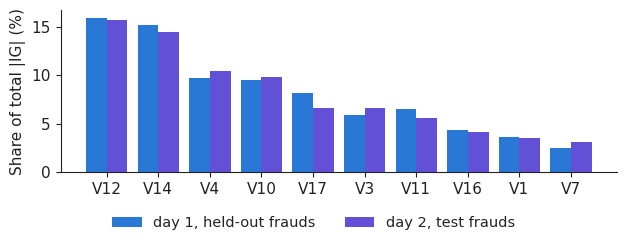

In [5]:
show('shift.n1', 'held-out frauds, day 1', int(len(F1v))); show('shift.n2', 'test frauds, day 2', int(len(F2)))
g1, g2 = np.abs(ig(F1v)).mean(0), np.abs(ig(F2)).mean(0); p1, p2 = g1 / g1.sum(), g2 / g2.sum()
print('Spearman day 1 vs day 2:', round(stats.spearmanr(g1, g2)[0], 2)); top = np.argsort(-(g1 + g2))[:10]; xs = np.arange(10)
fig, ax = plt.subplots(figsize=(6.4, 2.5)); ax.bar(xs - 0.2, 100 * p1[top], width=0.4, color=PAL['train'], label='day 1, held-out frauds')
ax.bar(xs + 0.2, 100 * p2[top], width=0.4, color=PAL['test'], label='day 2, test frauds'); ax.set_xticks(xs); ax.set_xticklabels([FF[j] for j in top])
ax.set_ylabel('Share of total |IG| (%)'); legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('time_shift.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()